<a href="https://colab.research.google.com/github/HKozuka/IDX-Exchange-Data-Science/blob/main/06_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Further Evaluation: Metric Expansion & Trucated Models

## 1. Setup

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from sklearn.metrics import r2_score, mean_squared_error

# Plot styling used throughout: one series color, quiet gray ink for axes and reference lines
BLUE, INK = '#2a78d6', '#52514e'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'axes.edgecolor': INK})

In [4]:
BASE_PATH = '/content/drive/MyDrive/IDX Exchange Data Science Internship/Google Colab Notebooks/'
TARGET = 'log_ClosePrice'
SEED = 42

df_clean = pd.read_csv(f'{BASE_PATH}X_after_feat_engin.csv')                 # training source
df_test_raw = pd.read_csv(f'{BASE_PATH}test_dataset_after_feat_eng.csv')     # holdout
print('df_clean:', df_clean.shape, '| test:', df_test_raw.shape)
df_clean.head()

df_clean: (307648, 48) | test: (12401, 47)


,Unnamed: 0,log_ClosePrice,CloseDate,ViewYN,WaterfrontYN,PoolPrivateYN,Stories,FireplaceYN,AssociationFeeFrequency,log_LivingArea,...,SqftPerBedroom,Zip_ppsf_6m,Zip_sales_6m,Nbhd_ppsf_6m,Nbhd_logprice_est,Comp_ppsf,Comp_logprice_est,Comp_size_diff,Comp_dist_km,CoastDist_km
0,0,13.610943,2024-01-05,0.0,0.0,0.0,2.0,0.0,NaN,7.588324,...,493.5,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,2.125725
1,1,13.604790,2024-01-05,0.0,0.0,0.0,2.0,0.0,NaN,7.588324,...,493.5,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,2.102132
2,2,14.557448,2024-01-02,1.0,0.0,0.0,2.0,1.0,NaN,8.226038,...,934.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,12.654789
3,3,14.665661,2024-01-31,1.0,0.0,0.0,1.0,1.0,NaN,7.800982,...,610.5,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,26.790793
4,4,13.873779,2024-01-16,1.0,0.0,0.0,1.0,1.0,NaN,7.559038,...,639.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,26.995806


## 2. Features and Time-Based Folds
Same feature matrix and expanding-window folds as `04_model_comparison.ipynb` and `05_advanced_models.ipynb`, so every number here lines up with those notebooks.

In [5]:
import time, shutil
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor

df_clean = df_clean.drop(columns=['Unnamed: 0'], errors='ignore')
test = df_test_raw.drop(columns=['Unnamed: 0'], errors='ignore')

DROP = [TARGET, 'CloseDate', 'AssociationFee']   # AssociationFee is replaced by HOA_Monthly

def to_xy(df, feature_cols=None):
    """Numeric feature matrix and target. Pass feature_cols to match the training columns."""
    X = df.drop(columns=[c for c in DROP if c in df.columns])
    X = X.select_dtypes(include='number').astype(float).replace([np.inf, -np.inf], np.nan)
    if feature_cols is not None:
        missing = set(feature_cols) - set(X.columns)
        if missing:
            print('WARNING, missing columns:', missing)
        X = X.reindex(columns=feature_cols)
    return X, df[TARGET]

X_all, y_all = to_xy(df_clean)
FEATURES = list(X_all.columns)
X_test, y_test = to_xy(test, FEATURES)

def make_key(d):
    """Address + close date + listing date, used to find each fold's rows in df_clean."""
    return (d['UnparsedAddress'].astype(str) + '|' +
            pd.to_datetime(d['CloseDate']).dt.strftime('%Y-%m-%d') + '|' +
            pd.to_datetime(d['ListingContractDate']).dt.strftime('%Y-%m-%d'))

clean_key = make_key(df_clean)
close_dates = pd.to_datetime(df_clean['CloseDate'])
cv_splits = []
for k in range(1, 6):
    fold = pd.read_csv(f'{BASE_PATH}validation_fold_{k}.csv')
    val_mask = clean_key.isin(set(make_key(fold))).values
    train_mask = (close_dates < close_dates[val_mask].min()).values & ~val_mask
    cv_splits.append((k, train_mask, val_mask))
    print(f'fold {k}: train {train_mask.sum():,}, validate {val_mask.sum():,}')
print(f'{len(FEATURES)} features | train {X_all.shape} | test {X_test.shape}')

fold 1: train 48,810, validate 49,213
fold 2: train 98,228, validate 49,205
fold 3: train 147,305, validate 49,206
fold 4: train 196,360, validate 49,209
fold 5: train 245,586, validate 49,203
39 features | train (307648, 39) | test (12401, 39)


## 3. Metrics Beyond R²
R² is computed on `log_ClosePrice`, so it says how much log-price variance the model explains, not how far off a typical prediction is in dollars. Percentage errors on the dollar scale answer that directly and put a 400k dollar home and a 4 million dollar home on equal footing.

For each home $i$, with actual sale price $y_i$ and predicted price $\hat{y}_i = e^{\widehat{\log y_i}} - 1$:

$$\text{APE}_i = \frac{|\hat{y}_i - y_i|}{y_i} \qquad \text{MAPE} = \frac{1}{n}\sum_{i=1}^{n} \text{APE}_i \qquad \text{MdAPE} = \operatorname{median}(\text{APE}_1, \dots, \text{APE}_n)$$

- **MAPE** is the average miss. A handful of very large misses (often data-entry errors or unusual sales) can pull it up.
- **MdAPE** is the *miss on the typical home*: half of predictions are closer than this, half are further off. It is the standard headline number for automated valuation models.
- **Median signed % error** $\operatorname{median}\left(\frac{\hat{y}_i - y_i}{y_i}\right)$ shows direction: negative means the model tends to underpredict.

In [6]:
def price_metrics(log_true, log_pred):
    """R2 on the log scale plus dollar-scale percentage errors."""
    log_true, log_pred = np.asarray(log_true), np.asarray(log_pred)
    actual, pred = np.expm1(log_true), np.expm1(log_pred)
    pct = (pred - actual) / actual
    ape = np.abs(pct)
    return {'n': len(actual),
            'R2 (log)': r2_score(log_true, log_pred),
            'MAPE': ape.mean(),
            'MdAPE': np.median(ape),
            'Median signed % error': np.median(pct),
            'Within 5%': (ape <= 0.05).mean(),
            'Within 10%': (ape <= 0.10).mean(),
            'Median abs. error ($)': np.median(np.abs(pred - actual))}

PCT_COLS = ['MAPE', 'MdAPE', 'Median signed % error', 'Within 5%', 'Within 10%']
FMT = {**{c: '{:.1%}' for c in PCT_COLS}, 'R2 (log)': '{:.4f}', 'n': '{:,.0f}',
       'Median abs. error ($)': '${:,.0f}'}

# Very low recorded prices make APE explode, so check how many there are
print('Test sales under $50,000:', int((np.expm1(y_test) < 50_000).sum()))
print('Training sales under $50,000:', int((np.expm1(y_all) < 50_000).sum()))

Test sales under $50,000: 0
Training sales under $50,000: 0


## 4. Models
The two finalists, with the settings chosen in earlier notebooks:
- **Random Forest** (`04`): `max_depth=30`, 100 trees, `max_samples=0.2`, `max_features=0.5`
- **XGBoost** (`05`): `max_depth=8`, `learning_rate=0.05`, 500 trees, `subsample=0.8`, `colsample_bytree=0.8`

In [7]:
DEVICE = 'cuda' if shutil.which('nvidia-smi') else 'cpu'
print('XGBoost device:', DEVICE)

MODELS = {
    'Random Forest': lambda: RandomForestRegressor(n_estimators=100, max_depth=30, max_samples=0.2,
                                                   max_features=0.5, n_jobs=-1, random_state=SEED),
    'XGBoost': lambda: xgb.XGBRegressor(n_estimators=500, max_depth=8, learning_rate=0.05,
                                        subsample=0.8, colsample_bytree=0.8, tree_method='hist',
                                        device=DEVICE, n_jobs=-1, random_state=SEED),
}

XGBoost device: cpu


## 5. Validation Predictions
Each model is refit on every fold's expanding training window, and its predictions on the fold are kept so the metrics can be computed per fold and pooled.

In [8]:
val_parts = []
for k, tr, va in cv_splits:
    t0 = time.time()
    part = pd.DataFrame({'fold': k, 'y': y_all[va].values}, index=df_clean.index[va])
    for name, make in MODELS.items():
        part[name] = make().fit(X_all[tr], y_all[tr]).predict(X_all[va])
    val_parts.append(part)
    print(f'fold {k}: {time.time() - t0:.0f}s')
val_preds = pd.concat(val_parts)

fold_rows = [{'model': name, 'fold': k, **price_metrics(g['y'], g[name])}
             for name in MODELS for k, g in val_preds.groupby('fold')]
fold_metrics = pd.DataFrame(fold_rows)
fold_metrics.pivot(index='model', columns='fold', values=['MAPE', 'MdAPE']).style.format('{:.1%}')

fold 1: 62s
fold 2: 99s
fold 3: 147s
fold 4: 196s
fold 5: 246s


## 6. Test Set Predictions
Refit both models on all of `df_clean` and score the held-out test set once.

In [9]:
test_preds = pd.DataFrame({'y': y_test.values}, index=test.index)
for name, make in MODELS.items():
    t0 = time.time()
    test_preds[name] = make().fit(X_all, y_all).predict(X_test)
    print(f'{name}: {time.time() - t0:.0f}s')

overall = pd.DataFrame(
    [{'model': name, 'split': 'Validation (5 folds pooled)', **price_metrics(val_preds['y'], val_preds[name])}
     for name in MODELS] +
    [{'model': name, 'split': 'Test', **price_metrics(test_preds['y'], test_preds[name])}
     for name in MODELS]).set_index(['split', 'model'])
overall.style.format(FMT)

Random Forest: 262s
XGBoost: 55s


## 7. Error by Price Band
Homes are grouped by **actual** sale price. Fixed dollar bands are easier to read than quantiles and match how buyers and agents talk about the market.

In [10]:
BAND_EDGES = [0, 500_000, 750_000, 1_000_000, 1_500_000, 2_500_000, np.inf]
BAND_LABELS = ['< $500k', '$500k to 750k', '$750k to 1M', '$1M to 1.5M', '$1.5M to 2.5M', '$2.5M+']

def band_table(preds):
    bands = pd.cut(np.expm1(preds['y']), BAND_EDGES, labels=BAND_LABELS, right=False)
    rows = []
    for name in MODELS:
        for band, g in preds.groupby(bands, observed=True):
            rows.append({'model': name, 'band': band, **price_metrics(g['y'], g[name])})
    out = pd.DataFrame(rows)
    out['share'] = out['n'] / len(preds)
    return out

test_bands = band_table(test_preds)
val_bands = band_table(val_preds)

BAND_COLS = ['n', 'share', 'MAPE', 'MdAPE', 'Median signed % error', 'Within 10%']
(test_bands.set_index(['model', 'band'])[BAND_COLS]
 .style.format({**FMT, 'share': '{:.1%}'}).set_caption('Test set'))

In [11]:
(val_bands.set_index(['model', 'band'])[BAND_COLS]
 .style.format({**FMT, 'share': '{:.1%}'}).set_caption('Validation (5 folds pooled)'))

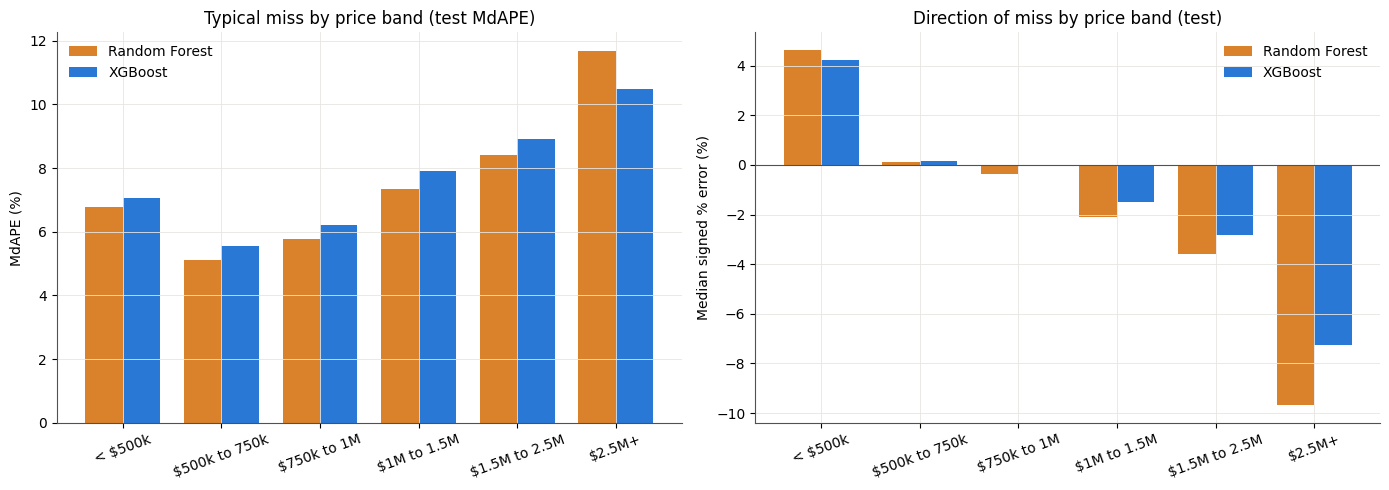

In [12]:
ORANGE = '#d9822b'
colors = {'Random Forest': ORANGE, 'XGBoost': BLUE}
x = np.arange(len(BAND_LABELS))
w = 0.38

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, name in enumerate(MODELS):
    t = test_bands[test_bands['model'] == name].set_index('band').reindex(BAND_LABELS)
    off = (i - 0.5) * w
    axes[0].bar(x + off, t['MdAPE'] * 100, w, color=colors[name], label=name)
    axes[1].bar(x + off, t['Median signed % error'] * 100, w, color=colors[name], label=name)

axes[0].set_title('Typical miss by price band (test MdAPE)')
axes[0].set_ylabel('MdAPE (%)')
axes[1].set_title('Direction of miss by price band (test)')
axes[1].set_ylabel('Median signed % error (%)')
axes[1].axhline(0, color=INK, linewidth=0.8)
for ax in axes:
    ax.set_xticks(x, BAND_LABELS, rotation=20)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 8. Scoping the Model to 500k to 2.5M

Section 7 shows **the model is weakest at the two ends of the market**: it overpredicts homes under 500k and underpredicts homes over 2.5M. This section asks what the metrics would look like if the model only had to price homes between 500k and 2.5M, which is about 78% of the test set.

Two versions are compared on the same in-range homes:

- **Full model, scored in range.** The models from sections 5 and 6, trained on every price, scored only on homes that sold between 500k and 2.5M. No retraining.
- **Range-trained model.** XGBoost refit on in-range training homes only, then scored on the same homes. This shows whether the model improves when it no longer has to fit the extremes.

**Caveat.** The range is defined by actual sale price, which is not known when a prediction is made. In practice the scope would be set by list price or by the model's own estimate, and some homes near 500k and 2.5M would land on the wrong side. A range-trained tree model also can never predict outside the range it was trained on, which caps its misses at the edges. Treat these numbers as an upper bound on what scoping can deliver.

In [13]:
LO, HI = 500000, 2500000

def in_range(log_y):
    """True for homes whose actual sale price is in [LO, HI)."""
    price = np.expm1(np.asarray(log_y))
    return (price >= LO) & (price < HI)

val_in = val_preds[in_range(val_preds['y'])]
test_in = test_preds[in_range(test_preds['y'])]
print(f'Validation homes in range: {len(val_in):,} of {len(val_preds):,} ({len(val_in) / len(val_preds):.1%})')
print(f'Test homes in range: {len(test_in):,} of {len(test_preds):,} ({len(test_in) / len(test_preds):.1%})')

Validation homes in range: 193,815 of 246,036 (78.8%)
Test homes in range: 9,648 of 12,401 (77.8%)


In [14]:
# Refit XGBoost on in-range homes only, using the same expanding-window folds
SCOPED = 'XGBoost (range-trained)'
train_in = in_range(y_all)

scoped_val = []
for k, tr, va in cv_splits:
    t0 = time.time()
    tr_s, va_s = tr & train_in, va & train_in
    model = MODELS['XGBoost']().fit(X_all[tr_s], y_all[tr_s])
    scoped_val.append(pd.Series(model.predict(X_all[va_s]), index=df_clean.index[va_s]))
    print(f'fold {k}: train {tr_s.sum():,}, validate {va_s.sum():,}, {time.time() - t0:.0f}s')
val_in = val_in.assign(**{SCOPED: pd.concat(scoped_val).reindex(val_in.index)})

model = MODELS['XGBoost']().fit(X_all[train_in], y_all[train_in])
test_in = test_in.assign(**{SCOPED: model.predict(X_test[in_range(test_preds['y'])])})

fold 1: train 37,657, validate 38,868, 26s
fold 2: train 76,687, validate 38,714, 31s
fold 3: train 115,286, validate 38,777, 35s
fold 4: train 153,942, validate 38,925, 42s
fold 5: train 192,894, validate 38,531, 47s


In [15]:
# Headline metrics: XGBoost on all homes for reference, then each model on in-range homes only
rows = []
for split, full, sub in [('Validation (5 folds pooled)', val_preds, val_in), ('Test', test_preds, test_in)]:
    rows.append({'split': split, 'model': 'XGBoost, all homes', **price_metrics(full['y'], full['XGBoost'])})
    for name in ['Random Forest', 'XGBoost', SCOPED]:
        rows.append({'split': split, 'model': f'{name}, 500k to 2.5M', **price_metrics(sub['y'], sub[name])})
scoped_metrics = pd.DataFrame(rows).set_index(['split', 'model'])
scoped_metrics.style.format(FMT)

In [16]:
# Does range training remove the pull toward the middle inside the range?
IN_BANDS = ['$500k to 750k', '$750k to 1M', '$1M to 1.5M', '$1.5M to 2.5M']

def scoped_band_table(sub):
    bands = pd.cut(np.expm1(sub['y']), BAND_EDGES, labels=BAND_LABELS, right=False)
    rows = [{'model': name, 'band': band, **price_metrics(g['y'], g[name])}
            for name in ['XGBoost', SCOPED]
            for band, g in sub.groupby(bands, observed=True) if band in IN_BANDS]
    return pd.DataFrame(rows).set_index(['model', 'band'])[['n', 'MdAPE', 'Median signed % error', 'Within 10%']]

display(scoped_band_table(test_in).style.format(FMT).set_caption('Test set, 500k to 2.5M'))
display(scoped_band_table(val_in).style.format(FMT).set_caption('Validation (5 folds pooled), 500k to 2.5M'))

In [21]:
# Collect every metric table from this notebook into one CSV
sm = scoped_metrics.reset_index()
sm = sm[~sm['model'].str.endswith('all homes')].assign(model=lambda d: d['model'].str.replace(', 500k to 2.5M', '', regex=False), scope='500k to 2.5M', band='All in range')
parts = [overall.reset_index().assign(scope='All homes', band='All'), test_bands.assign(split='Test', scope='All homes'), val_bands.assign(split='Validation (5 folds pooled)', scope='All homes'), sm, scoped_band_table(test_in).reset_index().query('model == @SCOPED').assign(split='Test', scope='500k to 2.5M'), scoped_band_table(val_in).reset_index().query('model == @SCOPED').assign(split='Validation (5 folds pooled)', scope='500k to 2.5M')]
summary = pd.concat([p.assign(band=p['band'].astype(str)) for p in parts], ignore_index=True)
cols = ['scope', 'split', 'model', 'band', 'n', 'R2 (log)', 'MAPE', 'MdAPE', 'Median signed % error', 'Within 5%', 'Within 10%', 'Median abs. error ($)']
summary = summary[cols].round(4)

In [22]:
# Saving metrics_summary.csv

#summary.to_csv(f'{BASE_PATH}metrics_summary.csv', index=False)

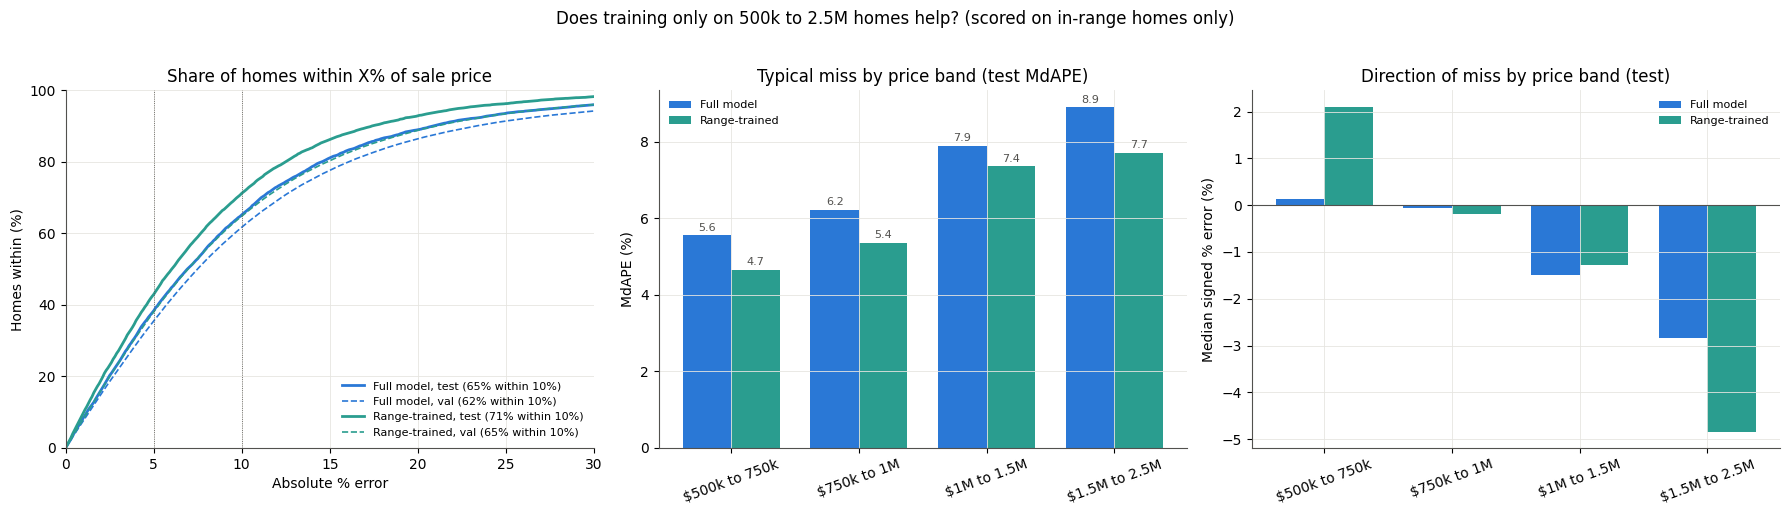

In [17]:
# Full XGBoost vs range-trained XGBoost, both scored on the same 500k to 2.5M homes
TEAL = '#2a9d8f'
pair = {'XGBoost': ('Full model', BLUE), SCOPED: ('Range-trained', TEAL)}

def ape(sub, name):
    actual, pred = np.expm1(sub['y']), np.expm1(sub[name])
    return np.sort(np.abs(pred - actual) / actual)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Share of homes within X% error: solid = test, dashed = validation
grid = np.linspace(0, 0.30, 301)
for name, (label, c) in pair.items():
    for sub, ls, split in [(test_in, '-', 'test'), (val_in, '--', 'val')]:
        a = ape(sub, name)
        within10 = np.searchsorted(a, 0.10, side='right') / len(a)
        axes[0].plot(grid * 100, np.searchsorted(a, grid, side='right') / len(a) * 100,
                     color=c, ls=ls, lw=2 if ls == '-' else 1.2,
                     label=f'{label}, {split} ({within10:.0%} within 10%)')
for t in (5, 10):
    axes[0].axvline(t, color=INK, lw=0.6, ls=':')
axes[0].set(title='Share of homes within X% of sale price', xlabel='Absolute % error',
            ylabel='Homes within (%)', xlim=(0, 30), ylim=(0, 100))

# 2 and 3. Typical miss and direction of miss by price band (test)
x, w = np.arange(len(IN_BANDS)), 0.38
tb = scoped_band_table(test_in)
for i, (name, (label, c)) in enumerate(pair.items()):
    t = tb.loc[name].reindex(IN_BANDS)
    off = (i - 0.5) * w
    bars = axes[1].bar(x + off, t['MdAPE'] * 100, w, color=c, label=label)
    axes[1].bar_label(bars, fmt='%.1f', fontsize=8, color=INK, padding=2)
    axes[2].bar(x + off, t['Median signed % error'] * 100, w, color=c, label=label)

axes[1].set(title='Typical miss by price band (test MdAPE)', ylabel='MdAPE (%)')
axes[2].set(title='Direction of miss by price band (test)', ylabel='Median signed % error (%)')
axes[2].axhline(0, color=INK, lw=0.8)
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes[1:]:
    ax.set_xticks(x, IN_BANDS, rotation=20)

fig.suptitle('Does training only on 500k to 2.5M homes help? (scored on in-range homes only)', y=1.02)
plt.tight_layout()
plt.show()

## 9. Insights

### Overall
| | Validation MAPE | Validation MdAPE | Test MAPE | Test MdAPE | Test within 10% |
|---|---|---|---|---|---|
| Random Forest | 13.4% | 8.3% | 10.7% | **6.8%** | **65.3%** |
| XGBoost | **12.5%** | **7.9%** | **10.3%** | 7.2% | 63.3% |

- **Errors are right-skewed.** MAPE runs about 1.5x MdAPE, and dropping the worst 1% of test predictions brings MAPE to 9.6% for both models. MdAPE is the headline number; MAPE tracks the tail.

### By price band (XGBoost)
| Price band | Share of test | Test MdAPE | Validation MdAPE | Median signed error (test) |
|---|---|---|---|---|
| Under 500k | 14% | 7.1% | 8.3% | +4.2% |
| 500k to 750k | 22% | **5.6%** | **6.2%** | +0.1% |
| 750k to 1M | 21% | 6.2% | 7.0% | 0.0% |
| 1M to 1.5M | 20% | 7.9% | 8.6% | -1.5% |
| 1.5M to 2.5M | 15% | 8.9% | 9.3% | -2.8% |
| 2.5M and up | 8% | 10.5% | 12.8% | -7.3% |

- **Most accurate from 500k to 1M**, with a typical miss near 6%.
- **Predictions are pulled toward the middle.** The model overpredicts homes under 500k by about 4% and underpredicts homes over 2.5M by about 7%, where the typical miss passes 10%.

### Scoping to 500k to 2.5M (XGBoost, same in-range homes)
| | Full model | Range-trained |
|---|---|---|
| Test MdAPE | 6.9% | **6.0%** |
| Test MAPE | 9.7% | **8.0%** |
| Test within 10% | 65.2% | **71.2%** |
| Test median abs. error | \$66,555 | **\$57,826** |
| Validation MdAPE | 7.5% | **7.0%** |
| Validation within 10% | 61.7% | **64.8%** |

- **Retraining does most of the work.** Scoring the full model only on in-range homes moves test MdAPE from 7.2% to 6.9%; retraining on those homes brings it to 6.0%. The gain holds in every band and on validation.
- **The pull toward the middle moves to the new edges.** Signed error goes from +0.1% to +2.1% in 500k to 750k and from -2.8% to -4.8% in 1.5M to 2.5M.
- **Treat this as an upper bound.** The range is set by actual sale price; in practice it would be set by list price or the model's own estimate.
